# Actividad | Dataset - Notebook

Nombre: Guillermo Sáenz González  
Matrícula: A00823049

## Secciones

- [Importar librerias](#importar-librerias)
- [Paso 1: Cargar y describir el dataset](#paso-1-cargar-y-describir-el-dataset)
- [Paso 2: Análisis Exploratorio (EDA)](#paso-2-análisis-exploratorio-eda)
- [Paso 3: Limpieza de datos](#paso-3-limpieza-de-datos)
- [Paso 4: Entrenamiento de modelo base](#paso-4-entrenamiento-de-modelo-base)
- [Paso 5: Evaluación del modelo](#paso-5-evaluación-del-modelo)
- [Paso 6: Registro de experimento en MLFlow](#paso-6-registro-de-experimento-en-mlflow)
- [Paso 7: Reflexión](#paso-7-reflexión)

# Importar librerias

In [1]:
import pandas
from matplotlib import pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay

import mlflow

c:\Users\gsaen\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Paso 1: Cargar y describir el dataset

## Cargar dataset

In [2]:
df_r = pandas.read_csv('./wine_quality/winequality-red.csv', delimiter=';')
df_r.columns = [col.replace(' ', '_') for col in df_r.columns]
df_r['color'] = 'red'

print('DataFrame shape:', df_r.shape)
df_r.head()

DataFrame shape: (1599, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
df_w = pandas.read_csv('./wine_quality/winequality-white.csv', delimiter=';')
df_w.columns = [col.replace(' ', '_') for col in df_w.columns]
df_w['color'] = 'white'

print('DataFrame shape:', df_w.shape)
df_w.head()

DataFrame shape: (4898, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,white
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,white
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,white
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,white
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,white


In [4]:
df = pandas.concat([df_r, df_w], ignore_index=True)

df

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white


## Describir dataset

### Registros

In [5]:
df.shape

(6497, 13)

### Tipos de columnas

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


### Variables

| Variable | Atributo | Unidades |
| --- | --- | --- |
| fixed_acidity | Fixed acidity | g(tartaric acid)/dm3 |
| volatile_acidity | Volatile acidity | g(acetic acid)/dm3 |
| citric_acid | Citric acid | g/dm3 |
| residual_sugar | Residual sugar | g/dm3 |
| chlorides | Chlorides | g(sodium chloride)/dm3 |
| free_sulfur_dioxide | Free sulfur dioxide | mg/dm3 |
| total_sulfur_dioxide | Total sulfur dioxide | mg/dm3 |
| density | Density | g/cm3 |
| pH | pH |  |
| suphates | Sulphates | g(potassium sulphate)/dm3 |
| alcohol | Alcohol | vol.% |

# Paso 2: Análisis Exploratorio (EDA)

## Estadísticas de variables

### Columnas numéricas

In [7]:
num_cols = df.select_dtypes(include=['number']).columns

desc_num = df.describe().T
desc_num['skewness'] = df[num_cols].skew()
desc_num['kurtosis'] = df[num_cols].kurt()

desc_num

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
fixed_acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000,1.723290,5.061161
volatile_acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000,1.495097,2.825372
citric_acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000,0.471731,2.397239
residual_sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000,1.435404,4.359272
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100,5.399828,50.898051
free_sulfur_dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000,1.220066,7.906238
total_sulfur_dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000,-0.001177,-0.371664
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898,0.503602,6.606067
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000,0.386839,0.367657
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000,1.797270,8.653699


### Columnas categóricas

In [8]:
cat_cols = df.select_dtypes(exclude=['number']).columns

desc_cat = df[cat_cols].describe().T

desc_cat

,count,unique,top,freq
color,6497,2,white,4898


## Distribución de variables de salida

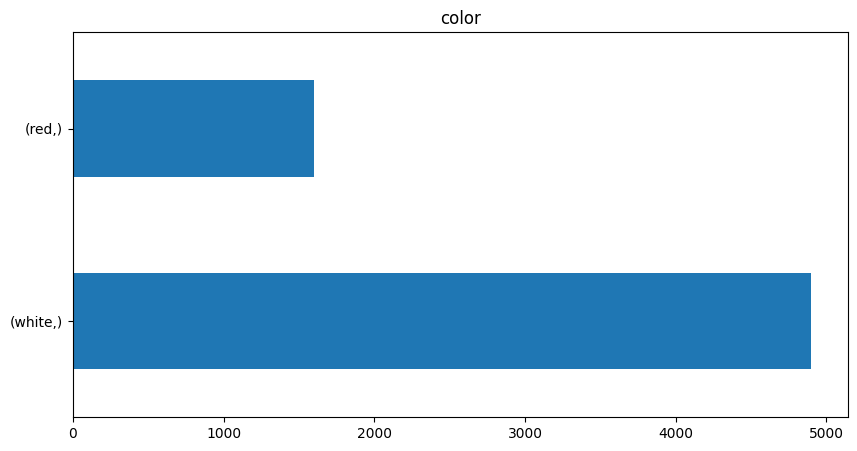

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

df[['color']].value_counts().plot.barh(ax=ax)
ax.set(title='color', ylabel=None);

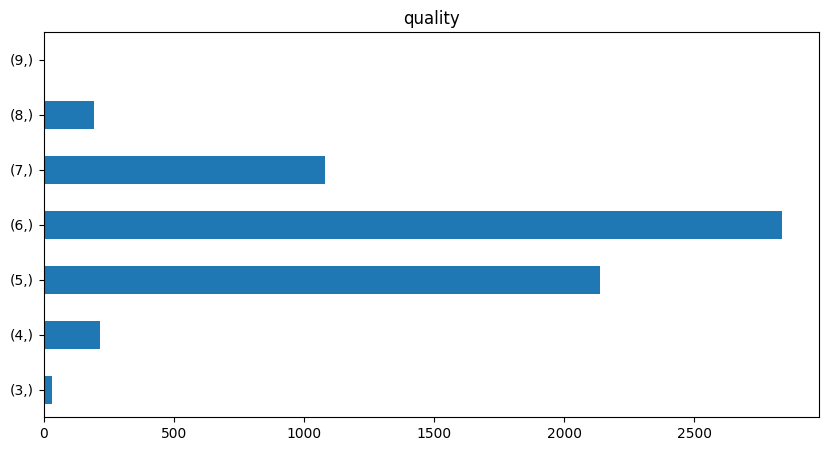

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

df[['quality']].value_counts().sort_index().plot.barh(ax=ax)
ax.set(title='quality', ylabel=None);

## Vino blanco vs rojo

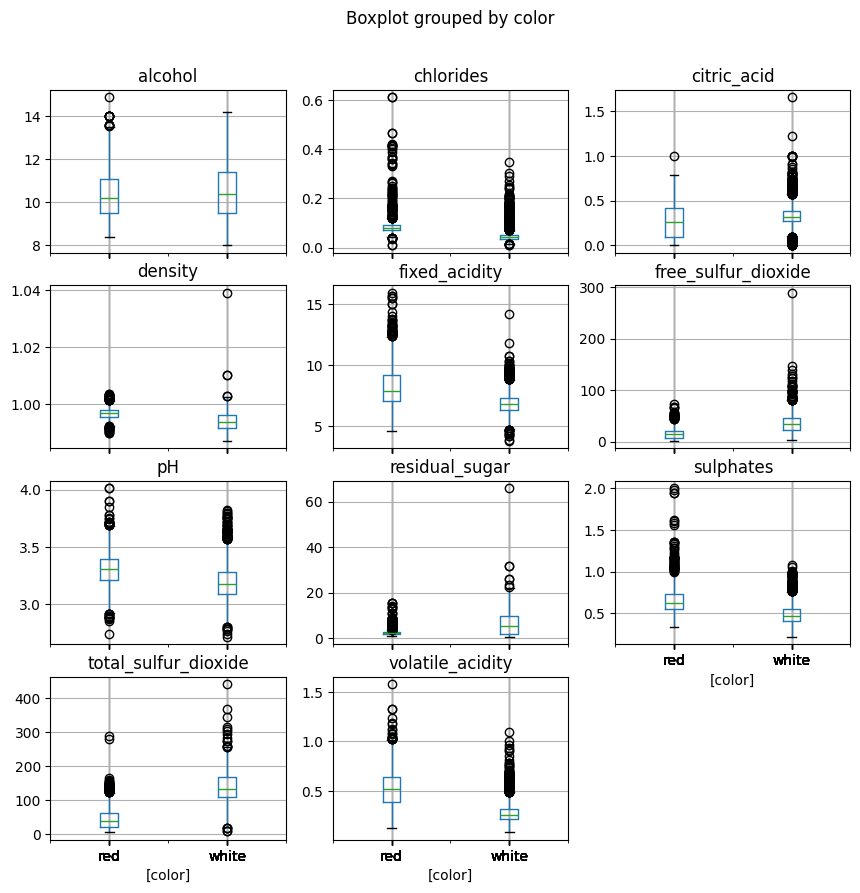

In [11]:
(
    df.drop(columns=['quality'])
    .boxplot(
        by='color',
        sharey=False,
        figsize=(10,10)
    )
);

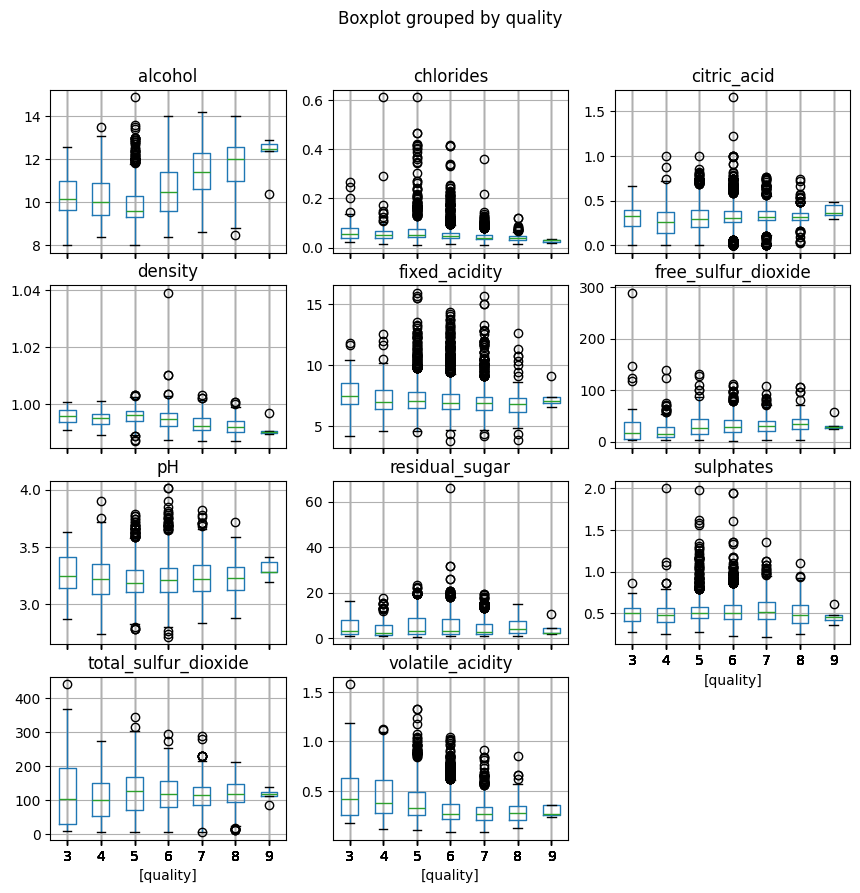

In [12]:
(
    df.drop(columns=['color'])
    .boxplot(
        by='quality',
        sharey=False,
        figsize=(10,10)
    )
);

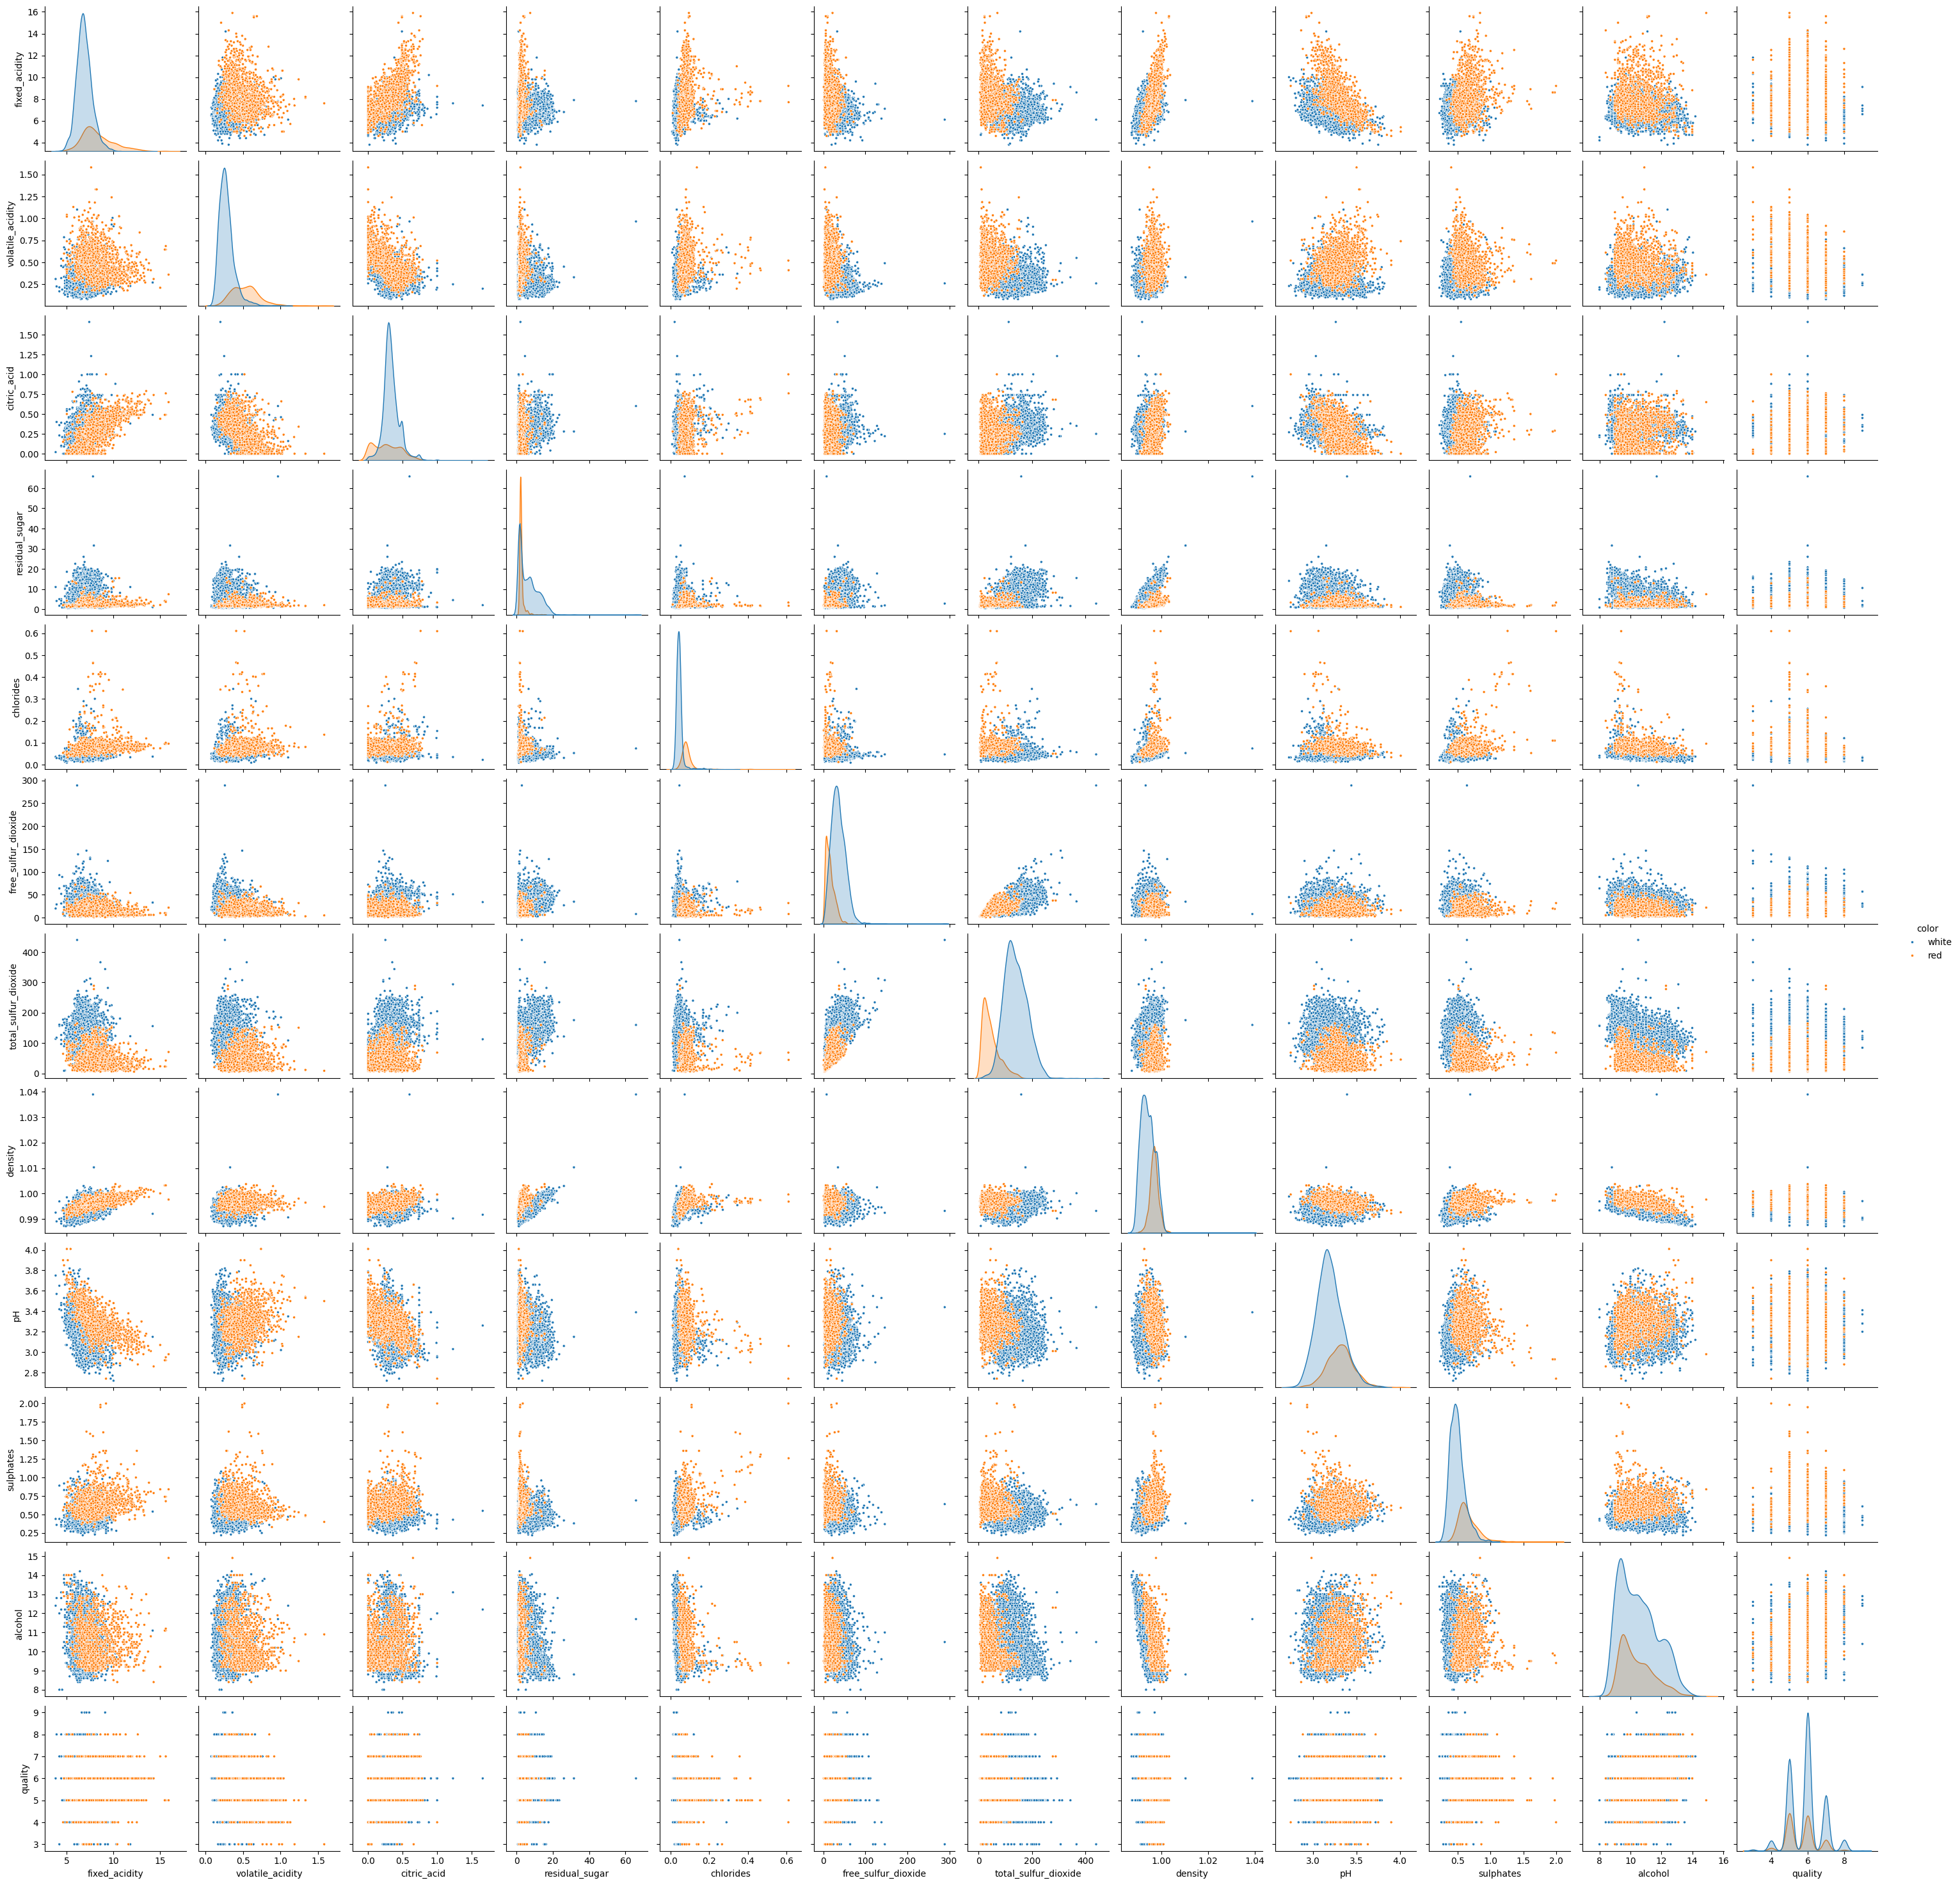

In [13]:
# sns.pairplot(df[num_cols], diag_kind='kde')
sns.pairplot(
    data=df.sort_values(by='color').sort_values(by='color', ascending=False),
    hue='color',
    markers='.'
)

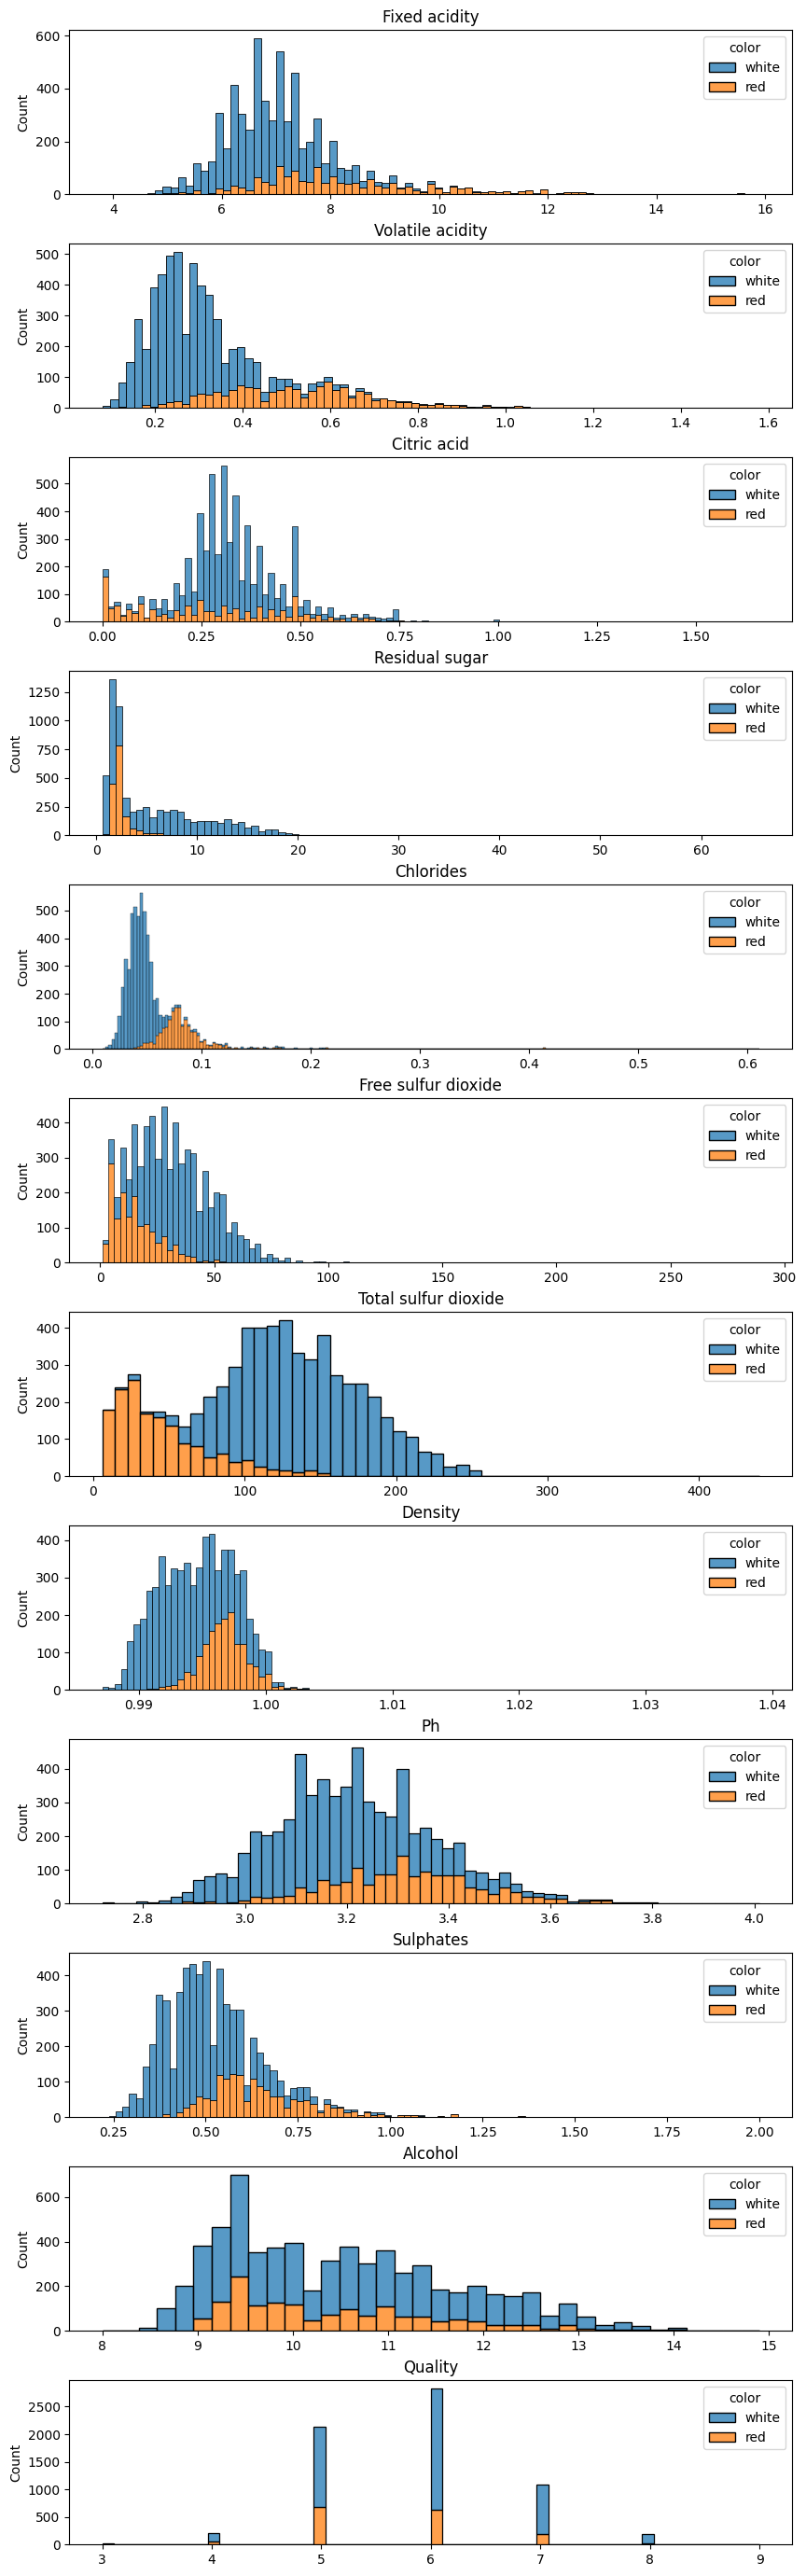

In [14]:
fig, axes = plt.subplots(len(num_cols), 1, figsize=(10,35))
fig.subplots_adjust(hspace=0.3)

for col, ax in zip(num_cols, axes):
    sns.histplot(
        data=df.sort_values(by='color', ascending=False),
        x=col, hue='color',
        multiple='stack', ax=ax
    )
    ax.set_title(col.replace('_', ' ').capitalize())
    ax.set_xlabel('')

# Paso 3: Limpieza de datos

## Valores faltantes

In [15]:
df.isna().sum()

fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
color                   0
dtype: int64

## Valores negativos inesperados

In [16]:
( df.drop(columns=['quality','color']) < 0 ).sum()

fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
dtype: int64

## Valores imposiblemente altos

In [17]:
( df[['pH']] > 14 ).sum()

pH    0
dtype: int64

## Resultado de la limpieza

El dataset no presenta problemas de valores faltantes, o fuera de los rangos esperados para cada variable.

Este dataset no requiere limpieza para empezar a analizarlo.

# Paso 4: Entrenamiento de modelo base

In [18]:
pearson_df = (
    df
    .drop(columns=['quality', 'color'])
    .corr('pearson', numeric_only=True)
)

pearson_pairs_df = ( pearson_df
    .reset_index()
    .rename(columns={'index':'C1'})
    .melt(id_vars=['C1'], var_name='C2', value_name='Corr')
    .query('C1 != C2')
)

pearson_pairs_df['C_Concat'] = pearson_pairs_df.apply(
    lambda r: min(r.C1, r.C2) + max(r.C1, r.C2),
    axis='columns'
)

high_corr_df = ( pearson_pairs_df
    .drop_duplicates(subset=['C_Concat'])
    .drop(columns=['C_Concat'])
    .sort_values(by='Corr', ascending=False)
    .reset_index(drop=True)
)

high_corr_df.head(10)

,C1,C2,Corr
0,total_sulfur_dioxide,free_sulfur_dioxide,0.720934
1,density,residual_sugar,0.552517
2,total_sulfur_dioxide,residual_sugar,0.495482
3,density,fixed_acidity,0.458910
4,free_sulfur_dioxide,residual_sugar,0.402871
5,sulphates,chlorides,0.395593
6,chlorides,volatile_acidity,0.377124
7,density,chlorides,0.362615
8,citric_acid,fixed_acidity,0.324436
9,sulphates,fixed_acidity,0.299568


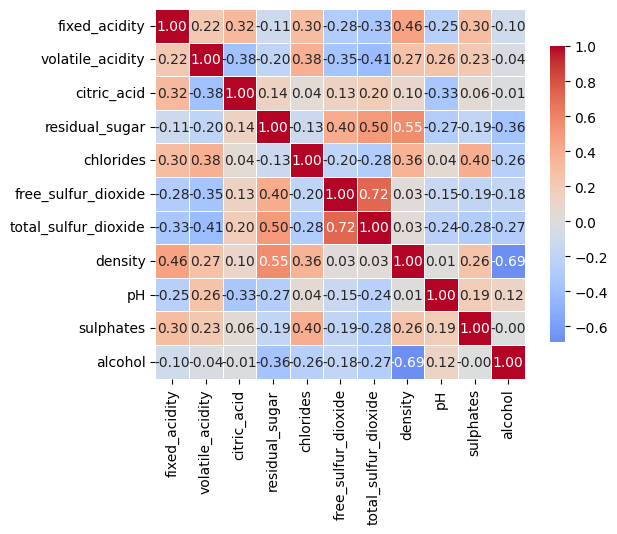

In [19]:
# Mapa de calor con la matriz de correlación

sns.heatmap(
    pearson_df, annot=True, fmt='.2f',
    cmap='coolwarm', center=0, square=True,
    linewidth=0.5, cbar_kws={'shrink':0.8},
);

In [20]:
# Separar variables predictoras (X) de la variable de salida (y)
X = df.drop(columns=['quality', 'color']).copy()
y = df[['color']].copy()

In [21]:
# Codificar categorias como 0 (Vino Rojo) y 1 (Vino Blanco)
y['color'].replace({
    'red': 0,
    'white': 1
}, inplace=True)

In [22]:
# Dividir el conjunto de datos en entrenamiento y prueba
test_size = 0.2
random_state = 1
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)

In [23]:
# Escoger variables para sacar del modelo
drop_cols = []

preprocessing = ColumnTransformer([
    ('Delete correlated columns', 'drop', drop_cols)
], remainder='passthrough')

In [24]:
pipeline = make_pipeline(
    preprocessing,
    LogisticRegression()
)

In [25]:
# Ajuste y predicciones
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

c:\Users\gsaen\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\gsaen\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Paso 5: Evaluación del modelo

In [26]:
# Función para evaluar modelos
def evaluate_model(y_true, y_pred):
    eval_fn_dict = {
        'Recall': recall_score,
        'Precision': precision_score,
        'Accuracy': accuracy_score
    }

    eval_score_dict = {}

    for metric, fn in eval_fn_dict.items():
        score_value = fn(y_true, y_pred)
        eval_score_dict[metric] = score_value
        print(f'- {metric}:\t{score_value}')
    
    return eval_score_dict

In [27]:
scores = evaluate_model(y_true=y_test, y_pred=y_pred)

- Recall:	0.9880358923230309
- Precision:	0.9860696517412936
- Accuracy:	0.98


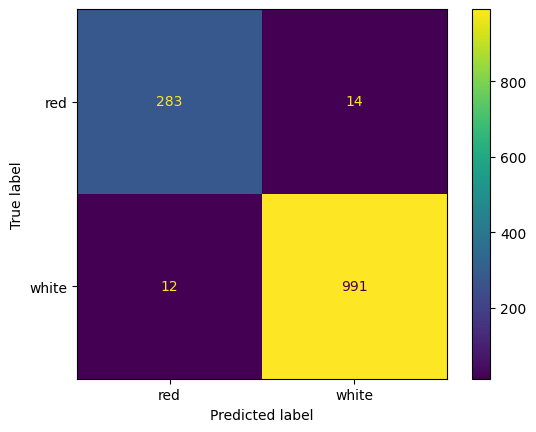

In [28]:
cm = confusion_matrix(y_true=y_test, y_pred=y_pred)
ConfusionMatrixDisplay(cm, display_labels=['red', 'white']).plot()

Se observa que el modelo entrenado puede sufrir de un sobreajuste.  
Puesto que las métricas obtenidas son demasiado altas para ser un modelo tan sencillo.

Otra cosa que pudo haber influido es la cantidad desproporcionada de registros de color blanco, contra los de color rojo.  
Esto puede causar que el modelo este sesgado para seleccionar el color blanco como resultado en situaciones donde existe una duda razonable sobre cuál será el mejor resultado.

Incluso si el modelo no tiene sobreajuste, valdría la pena revisar con una distribución de prueba y entrenamiento diferente, o aumentando (augmentation) los datos originales para remover cualquier duda sobre el correcto entrenamiento del modelo.

# Paso 6: Registro de experimento en MLFlow

In [34]:
mlflow.set_tracking_uri('http://127.0.0.1:5000')
mlflow.set_experiment('Notebook_Baseline')

print('Tracking URI:', mlflow.get_tracking_uri())
print('Experiment:', mlflow.get_experiment_by_name('Notebook_Baseline'))

Tracking URI: http://127.0.0.1:5000
Experiment: <Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1791153439666, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791153439666, lifecycle_stage='active', name='Notebook_Baseline', tags={}, trace_location=None, workspace='default'>


In [35]:
with mlflow.start_run(run_name='Notebook_Baseline') as run:
    mlflow.log_param(key='Test_Size', value=test_size)
    mlflow.log_param(key='Random_State', value=random_state)
    mlflow.log_param(key='Drop_Cols', value=drop_cols)

    for k in scores:
        mlflow.log_metric(key=k, value=scores[k])

🏃 View run Notebook_Baseline at: http://127.0.0.1:5000/#/experiments/1/runs/3b0ea019ca444e66994b5eab836b1dea
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


![](./mlflow_experiment.png)

# Paso 7: Reflexión

## Flujo elaborado

Lo primero que se hizo fue buscar un dataset que se prestara para realizar un análisis básico y un modelo base. Esto no solo permitió conseguir un dataset para la actividad, también el familiarizarse con las plataformas de Kaggle y UCI Machine Learning Repository.  
Tras comparar varios datasets, se optó por utilizar uno de calidad y color de vinos, por tener una definición lo suficientemente clara como para hacer un modelo base de regresión logística.

Durante el análisis exploratorio se descubrio que no habia una variable que pudiera identificar por si sola el color del vino, pero habia diferencias en la distribución de cada variable para cada color de vino.  
Además, al utilizar gráficos de distribución de valores, las variables más útiles para la distinción de color fueron quedando más claras. Principalmente el `total_sulfur_dioxide` y en menor medida `chlorides` & `volatile_acidity`. El resto de las variables todavía son útiles para diferenciar de que color se trata, pero en conjunto.

En este dataset no hubo necesidad de limpiar los datos, pero aún así se verifico que no hubiera valores faltantes o fuera de rango.  
Incluso cuando parece que los datos ya pasaron por un proceso de limpieza, es buena práctica asegurar que este sea el caso.

Antes de realizar el entrenamiento del modelo base, se verificó que no hubiera variables redundantes o que aportaran información similar. Al ver que no era el caso se procedió a realizar el entrenamiento de un modelo de regresión logística.

Por la naturaleza binaria de la variable de salida (color), se utilizaron métricas de Recall, Precision & Accuracy.  
Junto con estas también se utilizo una matriz de confusión para ilustrar los resultados.

El principal parámetro en esta regresión fue la selección de variables a partir de la correlación entre estas.  
Tanto este parametro como el tamaño del conjunto de pruebas, el random_state que permite repetir la partición de prueba y entrenamiento, y las métricas obtenidas fueron registradas como parte del experimento en MLflow.

Por lo pronto, esto aporta mayor facilidad para replicar el experimento o utilizar como base para comparar si en el futuro se decide correr otro experimento con diferentes parámetros.

## Mejoras

Para mejorar este flujo ayudaría el iterar por varios parámetros y utilizar MLflow para registrar estos junto con sus resultados.  
Más allá de esto, también sería una mejoría el versionar el dataset, así como guardar copias de los modelos más prometedores. De manera que exista un historial de modificaciones a los datos, si es que las hay, así como de los modelos entrenados para compararlos con mayor facilidad sobre nuevos datos o incluso sobre conjuntos sintéticos de prueba.

## Área profesional

Me desempeño como ingeniero de datos en una empresa automotriz.  
En esta área tengo la oportunida de ver como los proyectos nacen, empiezan desde la extracción de datos, y finalmente se utilizan para reportes, chatbots, análisis, o herramientas de software.

Dos retos comunes dentro de este contexto son:
- La repetibilidad de experimentos y resultados
- Control de versiones sobre datasets y modelos

El primero, porque incluso con apoyo de herramientas como git y ambientes virtuales, hay partes de la repetición de experimentos que todavía son manuales y se hacen a lo largo de libretas de código muy extensas. Aquí es donde veo que las prácticas de MLOps pueden ayudar a disminuir los tiempos de desarrollo, el error humano, y llevar un mejor control como equipo de estos proyectos.

El segundo, porque a pesar de apoyarnos con git, este destaca para el control de versiones de archivos de texto. La única manera de versionar un dataset sería si este se manejara unicamente en CSV, JSON o algún formato similarmente basado en texto. Pero esto es muy ineficiente. Además, la mayoría del tiempo los modelos se suelen guardar como bianrios, pickles o archivos que no necesariamente son de texto.  
Aqui es donde las prácticas y herramientas de MLOps podrían ayudar a mi equipo de trabajo a aplicar un control de versiones sobre nuestros datasets, a la vez que se identifican los modelos porducidos con diferentes versiones de un dataset o diferentes parámetros.